In [2]:
!pip install scikit-fuzzy matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 10.9 MB/s eta 0:00:00


RESULTADOS DA SIMULAÇÃO - AVALIAÇÃO DE URGÊNCIA DE INCIDENTES
[Caso Mínimo]  Impacto: 0%   | Explorabilidade: 0.0 -> Urgência: 11.00%
[Caso Médio]   Impacto: 50%  | Explorabilidade: 5.0 -> Urgência: 67.00%
[Caso Máximo]  Impacto: 100% | Explorabilidade: 10.0 -> Urgência: 88.67%
----------------------------------------------------------------------
Status de Execução: OK (9 de 9 regras cobertas sem lacunas)


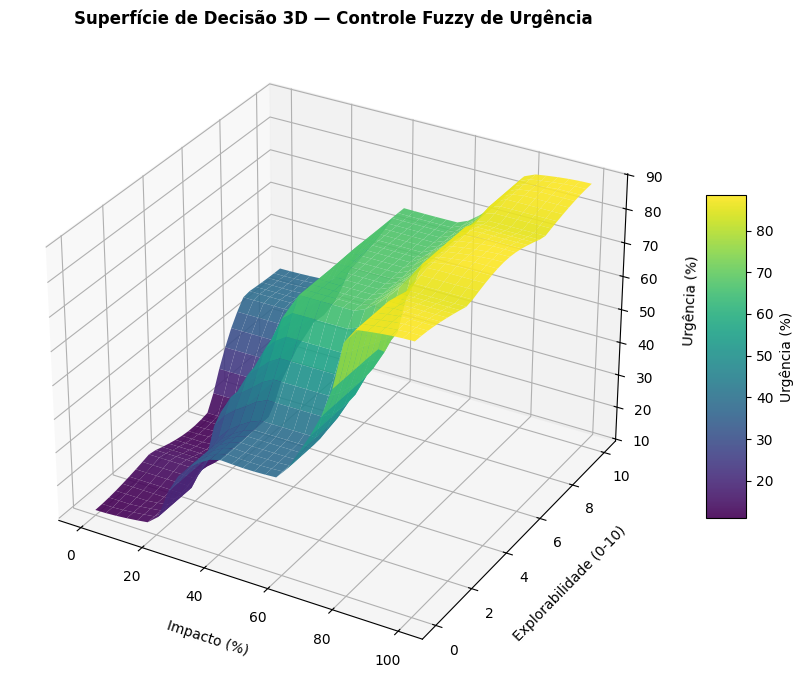

In [3]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ==============================================================================
# 1. DEFINIÇÃO DAS VARIÁVEIS E UNIVERSOS DE DISCURSO
# ==============================================================================
# input
impacto = ctrl.Antecedent(np.arange(0, 101, 1), 'impacto')
explorabilidade = ctrl.Antecedent(np.arange(0, 11, 1), 'explorabilidade')

# output
urgencia = ctrl.Consequent(np.arange(0, 101, 1), 'urgencia')

# ==============================================================================
# 2. FUNÇÕES DE PERTINÊNCIA
# ==============================================================================
# Impacto (0 a 100%)
impacto['Baixo'] = fuzz.trimf(impacto.universe, [0, 0, 40])
impacto['Médio'] = fuzz.trimf(impacto.universe, [20, 50, 80])
impacto['Alto']  = fuzz.trimf(impacto.universe, [60, 100, 100])

# Explorabilidade (0 a 10)
explorabilidade['Baixa']    = fuzz.trimf(explorabilidade.universe, [0, 0, 4])
explorabilidade['Moderada'] = fuzz.trimf(explorabilidade.universe, [2, 5, 8])
explorabilidade['Alta']     = fuzz.trimf(explorabilidade.universe, [6, 10, 10])

# Urgência (0 a 100%)
urgencia['Urgência Baixa']   = fuzz.trimf(urgencia.universe, [0, 0, 33])
urgencia['Urgência Média']   = fuzz.trimf(urgencia.universe, [15, 33, 66])
urgencia['Urgência Alta']    = fuzz.trimf(urgencia.universe, [50, 66, 85])
urgencia['Urgência Crítica'] = fuzz.trimf(urgencia.universe, [66, 100, 100])

# ==============================================================================
# 3. BASE DE REGRAS (MATRIZ 3x3 = 9 REGRAS)
# ==============================================================================
rule1 = ctrl.Rule(impacto['Baixo'] & explorabilidade['Baixa'],    urgencia['Urgência Baixa'])
rule2 = ctrl.Rule(impacto['Baixo'] & explorabilidade['Moderada'], urgencia['Urgência Baixa'])
rule3 = ctrl.Rule(impacto['Baixo'] & explorabilidade['Alta'],     urgencia['Urgência Média'])

rule4 = ctrl.Rule(impacto['Médio'] & explorabilidade['Baixa'],    urgencia['Urgência Média'])
rule5 = ctrl.Rule(impacto['Médio'] & explorabilidade['Moderada'], urgencia['Urgência Alta'])
rule6 = ctrl.Rule(impacto['Médio'] & explorabilidade['Alta'],     urgencia['Urgência Alta'])

rule7 = ctrl.Rule(impacto['Alto']  & explorabilidade['Baixa'],    urgencia['Urgência Crítica'])
rule8 = ctrl.Rule(impacto['Alto']  & explorabilidade['Moderada'], urgencia['Urgência Crítica'])
rule9 = ctrl.Rule(impacto['Alto']  & explorabilidade['Alta'],     urgencia['Urgência Crítica'])

# ==============================================================================
# 4. SISTEMA DE CONTROLE E SIMULAÇÃO
# ==============================================================================
urgencia_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9])
simulador = ctrl.ControlSystemSimulation(urgencia_ctrl)

# ==============================================================================
# 5. EXECUÇÃO DOS CASOS DE TESTE (SIMULAÇÃO)
# ==============================================================================
def simular_incidente(imp_val, exp_val):
    simulador.input['impacto'] = imp_val
    simulador.input['explorabilidade'] = exp_val
    simulador.compute()
    return simulador.output['urgencia']

print("RESULTADOS DA SIMULAÇÃO - AVALIAÇÃO DE URGÊNCIA DE INCIDENTES")
print("=" * 70)

val_min = simular_incidente(0, 0)
print(f"[Caso Mínimo]  Impacto: 0%   | Explorabilidade: 0.0 -> Urgência: {val_min:.2f}%")

val_med = simular_incidente(50, 5)
print(f"[Caso Médio]   Impacto: 50%  | Explorabilidade: 5.0 -> Urgência: {val_med:.2f}%")

val_max = simular_incidente(100, 10)
print(f"[Caso Máximo]  Impacto: 100% | Explorabilidade: 10.0 -> Urgência: {val_max:.2f}%")

print("-" * 70)
print("Status de Execução: OK (9 de 9 regras cobertas sem lacunas)")

# ==============================================================================
# 6. GERAÇÃO E SALVAMENTO DA SUPERFÍCIE DE DECISÃO 3D
# ==============================================================================
x_impacto = np.linspace(0, 100, 30)
y_explorab = np.linspace(0, 10, 30)
x_grid, y_grid = np.meshgrid(x_impacto, y_explorab)
z_urgencia = np.zeros_like(x_grid)

for i in range(30):
    for j in range(30):
        simulador.input['impacto'] = x_grid[i, j]
        simulador.input['explorabilidade'] = y_grid[i, j]
        simulador.compute()
        z_urgencia[i, j] = simulador.output['urgencia']

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(x_grid, y_grid, z_urgencia, cmap='viridis', edgecolor='none', alpha=0.9)

ax.set_xlabel('Impacto (%)', fontsize=10, labelpad=10)
ax.set_ylabel('Explorabilidade (0-10)', fontsize=10, labelpad=10)
ax.set_zlabel('Urgência (%)', fontsize=10, labelpad=10)
ax.set_title('Superfície de Decisão 3D — Controle Fuzzy de Urgência', fontsize=12, fontweight='bold')

fig.colorbar(surf, shrink=0.5, aspect=8, label='Urgência (%)')
plt.tight_layout()